In [36]:
import numpy as np
import matplotlib.pyplot as plt
import pygame

In [ ]:
#updates acceleration based on Newton's laws of gravitation
def acceleration(G, m, r):
    a = np.zeros_like(r)
    for i in range(len(m)):
        for j in range(len(m)):
            if(i != j):
                a[i] += -G*m[j]*(r[i]-r[j])/np.linalg.norm(r[i]-r[j])**3
    return a

In [ ]:
#advances the simulation using the "naive" Leapfrog integration method
def update_invleapfrog(ri, vi, a, dt):
    rf = np.empty_like(ri)
    vf = np.empty_like(vi)
    rf = ri + vi * dt
    vf = vi + a * dt
    return rf, vf

In [ ]:
#advances the simulation using the (correct) Leapfrog integration method
def update_leapfrog(ri, vi, a, dt):
    rf = np.empty_like(ri)
    vf = np.empty_like(vi)
    vf = vi + a * dt
    rf = ri + vf * dt
    return rf, vf

In [ ]:
#calculates the current kinetic and potential energies
def energy(G, m, r, v):
    U = 0
    E_kin = 0
    for i in range(5):
        E_kin += 1/2 * m[i] * np.linalg.norm(v[i])**2
        for j in range(i+1, 5, 1):
            U += -G * m[i] * m[j] / np.linalg.norm(r[i]-r[j])
    return U, E_kin

In [ ]:
W, H = 800, 600
R = 3
pygame.init()
screen = pygame.display.set_mode((W, H))
pygame.display.set_caption("n-body problem simulation")
clock = pygame.time.Clock()
running = True

#general constants of the simulation
G=10
dt=0.01

#position, velocity and mass matrices
r1 = np.array([400.0, 300.0])
r2 = np.array([500.0, 300.0])
r3 = np.array([200.0, 200.0])
r4 = np.array([310.0, 589.0])
r5 = np.array([0.0, 211.0])
r = np.array([r1,r2,r3,r4,r5])

v1 = np.array([1, 0])
v2 = np.array([0, -1])
v3 = np.array([0, 0])
v4 = np.array([0, 0])
v5 = np.array([0, 0])
v = np.array([v1,v2,v3,v4,v5])

m = np.array([100,10,1,0,0])

E = []
U = []
colors = ["yellow", "blue", "red", "green", "purple", "white", "orange"]

while running:
    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False 
    screen.fill("black")

    #drawing the bodies
    for i in range(len(m)):
        if(m[i] != 0):
            pygame.draw.circle(screen, colors[i%len(colors)], r[i], R)

    #energy and acceleration calculation
    U.append(energy(G,m,r,v)[0])
    E.append(energy(G,m,r,v)[1])
    a = acceleration(G,m,r)
    r,v = update_leapfrog(r,v,a,dt)

    pygame.display.flip()
    clock.tick(0)

pygame.quit()

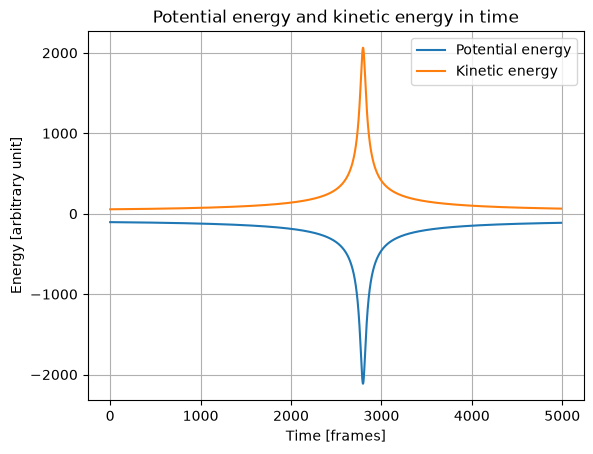

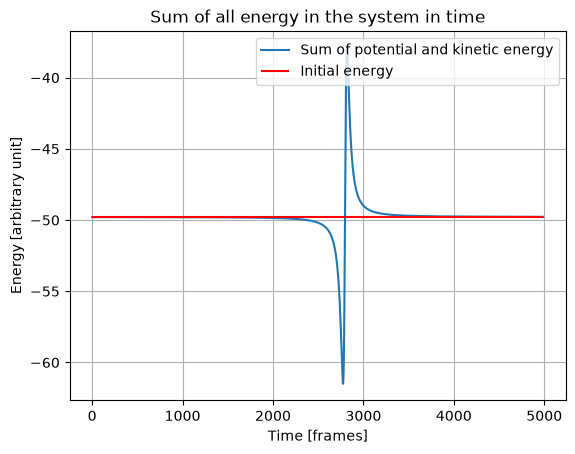

In [42]:
plt.figure()
t = range(0,len(E))

plt.plot(t,U, label="Potential energy")
plt.plot(t,E, label="Kinetic energy")
plt.grid()
plt.xlabel("Time [frames]")
plt.ylabel("Energy [arbitrary unit]")
plt.title("Potential energy and kinetic energy in time")
plt.legend()
plt.show()

plt.plot(t,np.add(E,U), label="Sum of potential and kinetic energy")
plt.hlines(E[0]+U[0],t[0],t[-1],"red", label="Initial energy")
plt.grid()
plt.xlabel("Time [frames]")
plt.ylabel("Energy [arbitrary unit]")
plt.title("Sum of all energy in the system in time")
plt.legend()